In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
import numpy as np
import random
import wandb
import os
# def set_seed(seed=42):
#     torch.manual_seed(seed)
#     np.random.seed(seed)
#     random.seed(seed)
# set_seed()
os.environ["WANDB_MODE"] = "offline"

wandb.init(
            project = "test-fl",
            entity= "whitewall_9-jinan-university",
            name= 'central_0.3',
)
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

Failed to detect the name of this notebook, you can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.


In [14]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import torch.nn.functional as F

# 1. 准备 MNIST 数据集（只取训练集）
transform = transforms.Compose([
    transforms.ToTensor(),                  # [0,255] -> [0.0,1.0], shape (1,28,28)
    transforms.Normalize((0.1307,), (0.3081,))
])
mnist_train = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
loader = DataLoader(mnist_train, batch_size=256, shuffle=False, num_workers=2)

# 2. 统计每个类别的样本总和与计数
num_classes = 10
# 累计向量和： shape (10, 784)
sum_vectors = torch.zeros((num_classes, 28*28), dtype=torch.float32)
# 每个类的样本数
counts = torch.zeros(num_classes, dtype=torch.long)

for imgs, labels in loader:
    # imgs: (B,1,28,28) -> 展平 (B,784)
    flat = imgs.view(-1, 28*28)
    for c in range(num_classes):
        mask = (labels == c)
        if mask.any():
            sum_vectors[c] += flat[mask].sum(dim=0)
            counts[c] += mask.sum()

# 3. 计算类均值向量
# 避免除以 0
mean_vectors = sum_vectors / counts.unsqueeze(1).float()   # shape (10, 784)

# 4. 计算余弦相似度矩阵
# 先将均值向量归一化
normed = F.normalize(mean_vectors, p=2, dim=1)             # 每行 L2 归一化
# 矩阵乘得到相似度 (10,10)
sim_matrix = torch.mm(normed, normed.t())

# 5. 打印结果
# 转为 numpy 更易阅读
import pandas as pd
df = pd.DataFrame(
    sim_matrix.cpu().numpy(),
    index=[str(i) for i in range(num_classes)],
    columns=[str(i) for i in range(num_classes)]
)
print("Digit Similarity Matrix (cosine between PyTorch mean-images):")
print(df.round(3))


ModuleNotFoundError: No module named 'pandas'

In [ ]:
import pandas as pd
df = pd.DataFrame(sim_matrix, index=range(10), columns=range(10))
print(df.round(3))


In [2]:
def generate_partial_labels(true_labels, num_classes=10, num_candidates=10):
    partial_labels = []
    for y in true_labels:
        candidates = {y}
        while len(candidates) < num_candidates:
            r = random.randint(0, num_classes - 1)
            candidates.add(r)
        partial_labels.append(sorted(list(candidates)))
    print(partial_labels)
    return partial_labels
def generate_partial_labels_prob(true_labels, num_classes=10, rho=0.5):
    partial_labels = []
    print(f'partital label rho: {rho}')
    for true_label in true_labels:
        other_labels = list(range(num_classes))
        other_labels.remove(true_label)

        candidate_labels = [true_label]
        for label in other_labels:
            if random.random() < rho:
                candidate_labels.append(label)

        if len(candidate_labels) == 1:
            random_irrelevant = random.choice(other_labels)
            candidate_labels.append(random_irrelevant)

        candidate_labels.sort()
        partial_labels.append(candidate_labels)
    # print(partial_labels)
    return partial_labels

In [3]:
class MNIST_PartialLabel(torch.utils.data.Dataset):
    def __init__(self, dataset, rho=0.0, num_classes=10, num_candidates=10):
        self.dataset = dataset
        self.num_classes = num_classes
        # self.partial_labels = generate_partial_labels([label for _, label in dataset], num_candidates=num_candidates)
        self.partial_labels = generate_partial_labels_prob([label for _, label in dataset], rho=rho)

    def __getitem__(self, index):
        img, true_label = self.dataset[index]
        partial_label = self.partial_labels[index]
        mask = torch.zeros(self.num_classes)
        mask[torch.tensor(partial_label, dtype=torch.long)] = 1.0

        return img, mask, true_label

    def __len__(self):
        return len(self.dataset)

partial_train_dataset = MNIST_PartialLabel(train_dataset, rho=0.3, num_candidates=5)
train_loader = torch.utils.data.DataLoader(partial_train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)


partital label rho: 0.3


In [4]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=10):
        super(SimpleCNN, self).__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(32 * 13 * 13, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)


In [5]:
def pll_loss(logits, candidate_labels):
    batch_size = logits.size(0)
    losses = []
    for i in range(batch_size):
        logits_i = logits[i]
        candidates = candidate_labels[i]
        log_probs = torch.log_softmax(logits_i, dim=0)
        loss_i = -log_probs[candidates].mean()
        losses.append(loss_i)
    return torch.stack(losses).mean()
def partial_label_loss(logits, mask):
        """
        logits: [B, C]
        mask: [B, C] (0/1 vector indicating candidate labels)
        """
        # Normalize mask to sum=1 over candidates (avoid bias)
        normalized_mask = mask / mask.sum(dim=1, keepdim=True)

        # Cross-entropy with soft labels
        log_probs = torch.log_softmax(logits, dim=1)
        loss = -(normalized_mask * log_probs).sum(dim=1).mean()
        return loss


In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
def evaluate(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, true_labels in loader:
            images = images.to(device)
            true_labels = true_labels.to(device)

            logits = model(images)
            preds = logits.argmax(dim=1)
            correct += (preds == true_labels).sum().item()
            total += true_labels.size(0)
    print(f"Test Accuracy: {correct / total * 100:.2f}%")
    return correct / total


cuda


In [10]:

model = SimpleCNN().to(device)
# optimizer = optim.Adam(model.parameters(), lr=1e-3)
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)


auc_list = []
avg_loss = 0.0
for epoch in range(100):
    model.train()
    total_loss = 0
    total_batches = 0
    for images, masks, true_labels in train_loader:
        images = images.to(device)
        masks = masks.to(device)
        # candidate_labels = [cl.to(device) for cl in candidate_labels]
        logits = model(images)

        # loss = pll_loss(logits, candidate_labels)
        loss = partial_label_loss(logits=logits, mask=masks)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_batches += 1
    accuracy = evaluate(model, test_loader)
    wandb.run.log({
                "accuracy": accuracy,
                "loss": total_loss / total_batches
            })
    auc_list.append(accuracy)
    
    print(f"Epoch {epoch + 1}, Loss: {total_loss:.4f}")


Test Accuracy: 57.46%
Epoch 1, Loss: 2154.5663
Test Accuracy: 67.27%
Epoch 2, Loss: 2142.8391
Test Accuracy: 69.92%
Epoch 3, Loss: 2132.0715
Test Accuracy: 73.50%
Epoch 4, Loss: 2121.4261
Test Accuracy: 75.68%
Epoch 5, Loss: 2111.3346
Test Accuracy: 77.10%
Epoch 6, Loss: 2102.3082
Test Accuracy: 79.12%
Epoch 7, Loss: 2094.6171
Test Accuracy: 80.20%
Epoch 8, Loss: 2088.3431
Test Accuracy: 81.82%
Epoch 9, Loss: 2083.4698
Test Accuracy: 81.55%
Epoch 10, Loss: 2079.6806
Test Accuracy: 83.67%
Epoch 11, Loss: 2076.7772
Test Accuracy: 84.15%
Epoch 12, Loss: 2074.4442
Test Accuracy: 84.46%
Epoch 13, Loss: 2072.4759
Test Accuracy: 85.10%
Epoch 14, Loss: 2070.8826
Test Accuracy: 85.54%
Epoch 15, Loss: 2069.4207
Test Accuracy: 86.10%
Epoch 16, Loss: 2068.1490
Test Accuracy: 86.10%
Epoch 17, Loss: 2066.9698
Test Accuracy: 86.48%
Epoch 18, Loss: 2065.9100
Test Accuracy: 86.92%
Epoch 19, Loss: 2064.9252
Test Accuracy: 87.19%
Epoch 20, Loss: 2063.9926
Test Accuracy: 87.43%
Epoch 21, Loss: 2063.1461
T

In [8]:
evaluate(model, test_loader)

Test Accuracy: 94.08%


0.9408

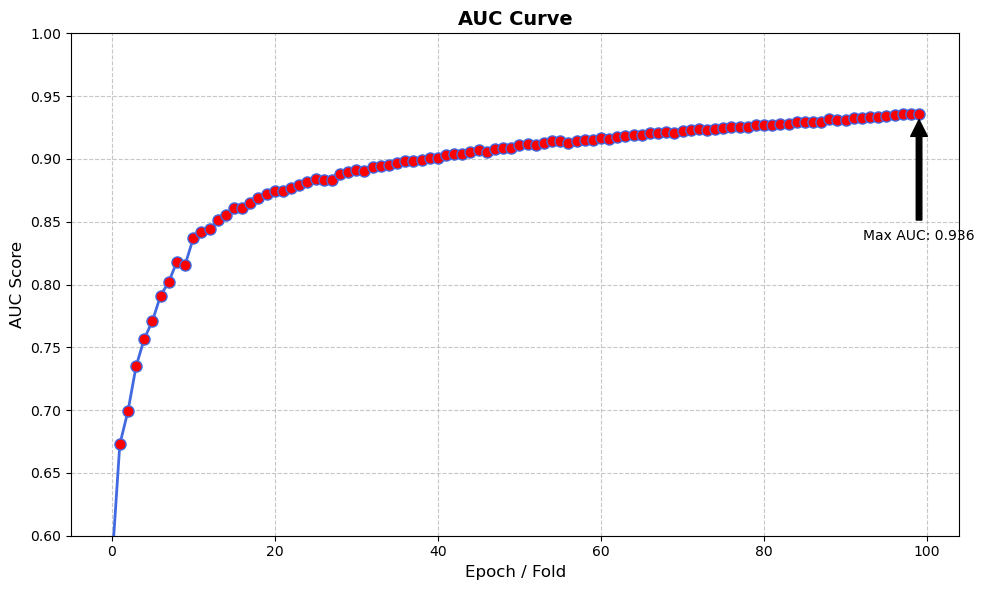

In [12]:

import matplotlib.pyplot as plt

# 假设这是你的AUC值列表（示例数据）
# auc_list = [0.65, 0.72, 0.78, 0.82, 0.85, 0.87, 0.89, 0.90, 0.91, 0.92]

# 创建画布
plt.figure(figsize=(10, 6))

# 绘制曲线图
plt.plot(auc_list, 
         marker='o',         # 数据点标记为圆圈
         linestyle='-',      # 实线连接
         linewidth=2,        # 线宽
         color='royalblue',  # 线条颜色
         markersize=8,       # 标记大小
         markerfacecolor='red')  # 标记填充色

# 添加标题和标签
plt.title('AUC Curve', fontsize=14, fontweight='bold')
plt.xlabel('Epoch / Fold', fontsize=12)
plt.ylabel('AUC Score', fontsize=12)

# 设置坐标轴范围
plt.ylim(0.6, 1.0)  # AUC范围通常是0.5-1.0

# 添加网格
plt.grid(True, linestyle='--', alpha=0.7)

# # 在数据点上方添加数值标签
# for i, value in enumerate(auc_list):
#     plt.text(i, value + 0.01, f'{value:.3f}', 
#              ha='center', va='bottom', fontsize=10)

# 显示最高AUC点
max_auc = max(auc_list)
max_index = auc_list.index(max_auc)
plt.annotate(f'Max AUC: {max_auc:.3f}', 
             xy=(max_index, max_auc),
             xytext=(max_index, max_auc - 0.1),
             arrowprops=dict(facecolor='black', shrink=0.05),
             ha='center')

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt

def plot_candidate_label_distribution(dataset, num_classes=10):
    count = np.zeros(num_classes)
    for _, candidate_labels, _ in dataset:
        count[candidate_labels] += 1  # 支持多标签加和
    plt.bar(range(num_classes), count)
    plt.xlabel("Class")
    plt.ylabel("Candidate label count")
    plt.title("Distribution of Candidate Labels")
    plt.show()
plot_candidate_label_distribution(train_loader)